In [1]:
import pandas as pd
import sys
sys.path.insert(0, "..")

from src.constants import DataFile
from src.paths import raw_file

dfs: dict[str, pd.DataFrame] = {}
for dataset in DataFile:
  dfs[dataset] = pd.read_csv(raw_file(dataset), sep="\t", index_col=0)
  print(dfs[dataset].shape)

(60660, 1226)
(1232, 3)
(1247, 193)


In [2]:
import numpy as np

star = dfs[DataFile.STAR_COUNTS]
rows_count = star.shape[0]
print((star.notna().sum() != rows_count).sum()) # no NAs in any cell
# almost all cols have at least 30% of zeros, no cols have more than 70% of zeros
for value in np.arange(0.3, 0.7, 0.1):
  print(((star == 0).sum() / rows_count > value).sum())

# star.T.describe()

0
1215
1168
179
0


In [3]:
cols_count = star.shape[1]
print((star.min() == 0).sum()/cols_count) # all cols have zero as a min value
# all genes have std > 1, 0.5% of genes have std > 4
for value in np.arange(1, 8):
  print((star.std(axis=1) > value).sum()/rows_count)

1.0
0.3696669963732278
0.03824596109462578
0.004747774480712166
0.0004780745136828223
3.297065611605671e-05
0.0
0.0


In [4]:
N = 5_000
std = star.std(axis=1)
star_filtered = star.loc[std.nlargest(N).index]

star_t = star_filtered.T
# Keep only primary tumor samples (barcode ends in -01A/B/C)
star_t = star_t[star_t.index.str.contains(r'-01[A-Z]$')]
star_t.index = star_t.index.str[:-1]
# Some patients have multiple primary tumor vials (01A, 01B) — keep first
star_t = star_t[~star_t.index.duplicated(keep='first')]
print(star_t.shape)
print(star_t.index.duplicated().sum())  # should be 0

(1095, 5000)
0


In [5]:
surv = dfs[DataFile.SURVIVAL]
print(surv.head(5))
print(surv.index.str.split('-').str[-1].unique().sort_values())
# 01 = primary tumor, 06 = metastatic, 11 = normal tissue

                  OS.time  OS      _PATIENT
sample                                     
TCGA-C8-A275-01A      1.0   0  TCGA-C8-A275
TCGA-AC-A7VC-01A      1.0   0  TCGA-AC-A7VC
TCGA-BH-A1F8-01A      1.0   1  TCGA-BH-A1F8
TCGA-BH-A1F8-11B      1.0   1  TCGA-BH-A1F8
TCGA-PL-A8LX-01A      5.0   0  TCGA-PL-A8LX
Index(['01A', '01B', '01C', '06A', '11A', '11B'], dtype='object', name='sample')


In [6]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

cl = dfs[DataFile.PAM50_CLINICAL]
print(cl.shape)
cols = cl.columns[cl.columns.str.lower().str.contains("subtype|pam|molecular")]
cl[cols].nunique()
cl[cols].apply(pd.Series.unique)
pam50 = "PAM50Call_RNAseq"
cl[pam50].value_counts()
cl.head(2)

(1247, 193)


,AJCC_Stage_nature2012,Age_at_Initial_Pathologic_Diagnosis_nature2012,CN_Clusters_nature2012,Converted_Stage_nature2012,Days_to_Date_of_Last_Contact_nature2012,Days_to_date_of_Death_nature2012,ER_Status_nature2012,Gender_nature2012,HER2_Final_Status_nature2012,Integrated_Clusters_no_exp__nature2012,Integrated_Clusters_unsup_exp__nature2012,Integrated_Clusters_with_PAM50__nature2012,Metastasis_Coded_nature2012,Metastasis_nature2012,Node_Coded_nature2012,Node_nature2012,OS_Time_nature2012,OS_event_nature2012,PAM50Call_RNAseq,PAM50_mRNA_nature2012,PR_Status_nature2012,RPPA_Clusters_nature2012,SigClust_Intrinsic_mRNA_nature2012,SigClust_Unsupervised_mRNA_nature2012,Survival_Data_Form_nature2012,Tumor_T1_Coded_nature2012,Tumor_nature2012,Vital_Status_nature2012,_INTEGRATION,_PANCAN_CNA_PANCAN_K8,_PANCAN_Cluster_Cluster_PANCAN,_PANCAN_DNAMethyl_BRCA,_PANCAN_DNAMethyl_PANCAN,_PANCAN_RPPA_PANCAN_K8,_PANCAN_UNC_RNAseq_PANCAN_K16,_PANCAN_miRNA_PANCAN,_PANCAN_mirna_BRCA,_PANCAN_mutation_PANCAN,_PATIENT,_cohort,_primary_disease,_primary_site,additional_pharmaceutical_therapy,additional_radiation_therapy,additional_surgery_locoregional_procedure,additional_surgery_metastatic_procedure,age_at_initial_pathologic_diagnosis,anatomic_neoplasm_subdivision,axillary_lymph_node_stage_method_type,axillary_lymph_node_stage_other_method_descriptive_text,bcr_followup_barcode,bcr_patient_barcode,bcr_sample_barcode,breast_cancer_surgery_margin_status,breast_carcinoma_estrogen_receptor_status,breast_carcinoma_immunohistochemistry_er_pos_finding_scale,breast_carcinoma_immunohistochemistry_pos_cell_score,breast_carcinoma_immunohistochemistry_prgstrn_rcptr_ps_fndng_scl,breast_carcinoma_primary_surgical_procedure_name,breast_carcinoma_progesterone_receptor_status,breast_carcinoma_surgical_procedure_name,breast_neoplasm_other_surgical_procedure_descriptive_text,cytokeratin_immunohistochemistry_staining_method_mcrmtstss_ndctr,days_to_additional_surgery_locoregional_procedure,days_to_additional_surgery_metastatic_procedure,days_to_birth,days_to_collection,days_to_death,days_to_initial_pathologic_diagnosis,days_to_last_followup,days_to_last_known_alive,days_to_new_tumor_event_additional_surgery_procedure,days_to_new_tumor_event_after_initial_treatment,disease_code,distant_metastasis_present_ind2,er_detection_method_text,er_level_cell_percentage_category,fluorescence_in_st_hybrdztn_dgnstc_prcdr_chrmsm_17_sgnl_rslt_rng,followup_case_report_form_submission_reason,form_completion_date,gender,her2_and_centromere_17_positive_finding_other_measuremnt_scl_txt,her2_erbb_method_calculation_method_text,her2_erbb_pos_finding_cell_percent_category,her2_erbb_pos_finding_fluorescence_n_st_hybrdztn_clcltn_mthd_txt,her2_immunohistochemistry_level_result,her2_neu_and_centromere_17_copy_number_analysis_npt_ttl_nmbr_cnt,her2_neu_breast_carcinoma_copy_analysis_input_total_number,her2_neu_chromosone_17_signal_ratio_value,her2_neu_metastatic_breast_carcinoma_copy_analysis_inpt_ttl_nmbr,histological_type,histological_type_other,history_of_neoadjuvant_treatment,hr2_n_nd_cntrmr_17_cpy_nmbr_mtsttc_brst_crcnm_nlyss_npt_ttl_nmbr,icd_10,icd_o_3_histology,icd_o_3_site,immunohistochemistry_positive_cell_score,informed_consent_verified,init_pathology_dx_method_other,initial_pathologic_diagnosis_method,initial_weight,is_ffpe,lab_proc_her2_neu_immunohistochemistry_receptor_status,lab_procedure_her2_neu_in_situ_hybrid_outcome_type,lost_follow_up,lymph_node_examined_count,margin_status,menopause_status,metastatic_breast_carcinm_ps_fndng_prgstrn_rcptr_thr_msr_scl_txt,metastatic_breast_carcinom_lb_prc_hr2_n_mmnhstchmstry_rcptr_stts,metastatic_breast_carcinoma_erbb2_immunohistochemistry_levl_rslt,metastatic_breast_carcinoma_estrogen_receptor_detection_mthd_txt,metastatic_breast_carcinoma_estrogen_receptor_status,metastatic_breast_carcinoma_estrogen_receptr_lvl_cll_prcnt_ctgry,metastatic_breast_carcinoma_her2_erbb_method_calculatin_mthd_txt,metastatic_breast_carcinoma_her2_erbb_pos_findng_cll_prcnt_ctgr

In [7]:
merged = star_t.merge(cl, left_index=True, right_index=True, how="inner")
print(merged.shape)

(1095, 5193)


In [8]:
import plotly.express as px
from sklearn.decomposition import PCA

labels = merged[pam50]
pca = PCA(n_components=3)
components = pca.fit_transform(star_t)
df_3d = pd.DataFrame(components, columns=["PC1", "PC2", "PC3"])
df_3d["subtype"] = labels.values

px.scatter_3d(df_3d, x="PC1", y="PC2", z="PC3", color="subtype")

In [9]:
df_3d["subtype"] = merged["tissue_source_site"].values

px.scatter_3d(df_3d, x="PC1", y="PC2", z="PC3", color="subtype")

In [10]:
print(pca.explained_variance_ratio_)


[0.13593796 0.09162113 0.04060309]


In [11]:
from umap import UMAP

reducer = UMAP(n_components=2)
embedding = reducer.fit_transform(star_t)


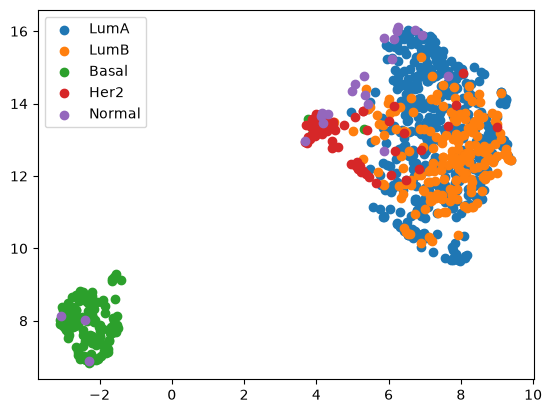

In [12]:
import matplotlib.pyplot as plt

emb = pd.DataFrame(embedding, columns=["x", "y"], index=star_t.index)
for subtype in labels.dropna().unique():
    mask = labels == subtype
    plt.scatter(emb.loc[mask, "x"], emb.loc[mask, "y"], label=subtype)
plt.legend()

In [13]:
print(labels.value_counts(dropna=False))
labels[labels.isna()].index[:5]
cl.index.isin(labels[labels.isna()].index).sum()
merged["PAM50Call_RNAseq"].isna().sum()
cl["PAM50Call_RNAseq"].isna().sum()

PAM50Call_RNAseq
LumA      421
NaN       253
LumB      192
Basal     139
Her2       67
Normal     23
Name: count, dtype: int64


np.int64(291)

In [14]:
labels = labels.dropna()
star_filtered_clean = star_t.loc[labels.index]

star_filtered_clean.to_csv("../data/interim/star_filtered.csv.gz")
labels.to_csv("../data/interim/labels.csv.gz")
